# 08_make_figures

Vẽ hình cho Thí nghiệm B, C, D từ các file kết quả JSON (chạy lại được bất cứ lúc nào).

## Mục tiêu và cách đọc

Vẽ lại biểu đồ từ kết quả B/C/D, không huấn luyện. Chạy notebook này sau 04/05/06 để cập nhật hình theo số liệu mới.

## Cách sử dụng

1. Chọn kernel Python có `ipykernel`, `numpy`, `torch`, `matplotlib`.
2. Giữ `RUN_EXPERIMENT = False` và chọn **Run All** để xem dữ liệu sẵn có.
3. Đổi thành `True` nếu muốn thực hiện lại; chạy tuần tự các ô từ đầu.
4. **Ctrl+S / Cmd+S** lưu toàn bộ output vào notebook. Báo cáo HTML và CSV được xuất tự động ở ô cuối.

**Lưu ý:** các hình B/C/D là file đã lưu; sau khi đổi kết quả, chạy notebook 08 để vẽ lại trước khi dùng hình trong bài. Thời điểm xuất báo cáo không phải thời điểm thực hiện thí nghiệm gốc.


## 1. Thiết lập và chọn chế độ

Cài môi trường một lần theo `HUONG_DAN_NOTEBOOK.md`. Mỗi lần chạy tạo thư mục riêng trong `results/notebook_runs/`. Khi chạy lại thí nghiệm, các kết quả chuẩn và checkpoint hiện có được sao lưu trước.

In [ ]:
from pathlib import Path
import os
import sys

# Tìm 02_demo dù kernel bắt đầu ở thư mục workspace hoặc thư mục notebook.
candidates = [Path.cwd(), *Path.cwd().parents]
DEMO_ROOT = next((base / suffix for base in candidates
                  for suffix in ("", "02_demo", "Gk_XLDL/02_demo")
                  if (base / suffix / "posit_lab/numformats.py").is_file()), None)
if DEMO_ROOT is None:
    raise FileNotFoundError("Mở notebook trong workspace chứa Gk_XLDL/02_demo.")
DEMO_ROOT = DEMO_ROOT.resolve()
os.chdir(DEMO_ROOT)
if str(DEMO_ROOT) not in sys.path:
    sys.path.insert(0, str(DEMO_ROOT))
from notebook_tools.reporting import NotebookRun

# False: xem số liệu sẵn có. True: chạy code thí nghiệm bên dưới.
RUN_EXPERIMENT = False
SCRIPT_ARGS = []
__file__ = str(DEMO_ROOT / '08_make_figures.py')
__package__ = None
session = NotebookRun(DEMO_ROOT, '08_make_figures.py', RUN_EXPERIMENT, SCRIPT_ARGS)
print("Thư mục lưu lần này:", session.out)

# Cell magic giữ code thẳng hàng; vẫn áp dụng chế độ chạy và lưu nhật ký.
from IPython.core.magic import register_cell_magic
import __future__

@register_cell_magic
def experiment(line, cell):
    if not RUN_EXPERIMENT:
        print("Đã bỏ qua tính toán; đặt RUN_EXPERIMENT = True để chạy ô này.")
        return
    with session.execute():
        code = compile(cell, str(session.source), "exec",
                       flags=__future__.annotations.compiler_flag)
        exec(code, get_ipython().user_ns)


## 2. fig_B

Mã chuyển nguyên từ `08_make_figures.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
"""Vẽ hình cho Thí nghiệm B, C, D từ các file kết quả JSON (chạy lại được bất cứ lúc nào)."""
import json
import os
from collections import defaultdict

import numpy as np

from posit_lab.plotstyle import setup, plt, FMT_COLOR, FMT_MARK, INK2, MUTED, C

HERE = os.path.dirname(os.path.abspath(__file__))
RES, FIG = os.path.join(HERE, "results"), os.path.join(HERE, "figures")
setup()


def fig_B():
    d = json.load(open(os.path.join(RES, "04_expB_weight_ptq.json")))
    base = d["B1"][0]["acc_mean"]
    sweep = d["B2_sweep"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for ax, mode, title in [(axes[0], "none", "Không co giãn (làm tròn trực tiếp)"),
                            (axes[1], "pow2", "Có co giãn theo lớp (hiệu chỉnh)")]:
        series = []
        for es in [0, 1, 2]:
            rows = [r for r in sweep if r["format"] == f"posit{r['bits']}_{es}" and r["scale"] == mode]
            series.append((f"Posit es={es}", f"posit_es{es}", rows))
        fp_rows = []
        for n in range(4, 9):
            cand = [r for r in sweep if r["bits"] == n and r["format"].startswith("fp") and r["scale"] == mode]
            fp_rows.append(max(cand, key=lambda r: r["acc_mean"]))
        series.append(("FP n-bit (số bit mũ tốt nhất)", "fp", fp_rows))
        if mode == "pow2":
            series.append(("INT n-bit (cắt tối ưu MSE)", "int",
                           [r for r in sweep if r["format"].startswith("int") and r["scale"] == "mse"]))
        for label, key, rows in series:
            rows = sorted(rows, key=lambda r: r["bits"])
            x = [r["bits"] for r in rows]
            y = [r["acc_mean"] for r in rows]
            e = [r["acc_std"] for r in rows]
            ax.errorbar(x, y, yerr=e, color=FMT_COLOR[key], marker=FMT_MARK[key], capsize=3,
                        lw=1.8, ms=6, label=label, mec="white", mew=1)
        ax.axhline(base, color=INK2, ls="--", lw=1)
        ax.text(8.05, base + 0.6, f"FP32 {base:.2f}%", color=INK2, fontsize=8, ha="right")
        ax.set_title(title, loc="left", fontsize=10.5)
        ax.set_xlabel("Số bit của trọng số")
        ax.set_xticks(range(4, 9))
        ax.set_ylim(60, 93)
        ax.legend(fontsize=8, loc="lower right")
    axes[0].set_ylabel("Độ chính xác test (%)")
    fig.suptitle("Thí nghiệm B · Lượng tử hóa trọng số LeNet-5 / Fashion-MNIST, không huấn luyện lại (TB ± độ lệch chuẩn, 3 mô hình)",
                 x=0.01, ha="left", fontsize=11)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG, "B_bit_sweep.png"))

    # Sai số tương đối của trọng số ở 8 bit
    rows = [r for r in d["B1"] if r["format"] != "fp32"]
    def lab(r):
        return f"{r['format']} ({r['scale']})"
    rows = sorted(rows, key=lambda r: r["rel_weight_err_mean"])
    rows = [r for r in rows if r["format"].endswith(("8_0", "8_1", "8_2")) or r["format"] in
            ("int8", "fp8e4m3", "fp8e5m2")]
    fig, ax = plt.subplots(figsize=(7.4, 4.2))
    def key(r):
        f = r["format"]
        return "int" if f.startswith("int") else "fp" if f.startswith("fp") else f"posit_es{f[-1]}"
    y = np.arange(len(rows))
    ax.barh(y, [100 * r["rel_weight_err_mean"] for r in rows], color=[FMT_COLOR[key(r)] for r in rows],
            height=0.7, edgecolor="white", linewidth=2)
    for i, r in enumerate(rows):
        ax.text(100 * r["rel_weight_err_mean"] + 0.1, i, f"{100 * r['rel_weight_err_mean']:.2f}%  "
                f"(acc {r['acc_mean']:.2f}%)", va="center", fontsize=8, color=INK2)
    ax.set_yticks(y, [lab(r) for r in rows], fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlabel("Sai số tương đối ‖W − Q(W)‖ / ‖W‖ (%), trung bình 5 lớp × 3 mô hình")
    ax.set_title("Thí nghiệm B · Sai số lượng tử hóa trọng số ở 8 bit (thấp hơn = giữ thông tin tốt hơn)",
                 loc="left", fontsize=10)
    ax.set_xlim(0, 7.5)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG, "B_weight_error_8bit.png"))
    print("-> B_bit_sweep.png, B_weight_error_8bit.png")




## 3. fig_C

Mã chuyển nguyên từ `08_make_figures.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
def fig_C():
    p = os.path.join(RES, "05_expC_quire.json")
    if not os.path.exists(p):
        print("(chưa có kết quả C)"); return
    d = json.load(open(p))
    # C1
    fig, ax = plt.subplots(figsize=(6.6, 3.8))
    c1 = [r for r in d["C1_dot_product"] if r["format"] == "posit8_1"]
    K = [r["K"] for r in c1]
    for mode, col, mk, lbl in [("quire", C["blue"], "o", "Quire (làm tròn 1 lần)"),
                               ("fma", C["orange"], "s", "FMA (làm tròn mỗi bước cộng)"),
                               ("sep", C["aqua"], "^", "Nhân & cộng làm tròn riêng")]:
        ax.plot(K, [100 * r[f"median_rel_err_{mode}"] for r in c1], color=col, marker=mk, label=lbl,
                mec="white", mew=1)
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Độ dài tích vô hướng K")
    ax.set_ylabel("Sai số tương đối trung vị (%)")
    ax.set_title("Thí nghiệm C1 · posit⟨8,1⟩: sai số tích vô hướng tăng theo K nếu không có quire",
                 loc="left", fontsize=10)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG, "C1_dot_product.png"))
    # C2
    agg = defaultdict(list)
    for r in d["C2_network"]:
        agg[(r["format"], r["accum"])].append(r["acc"])
    fmts = ["posit8_0", "posit8_1", "posit8_2", "fp8e4m3", "posit16_1"]
    names = {"posit8_0": "posit⟨8,0⟩", "posit8_1": "posit⟨8,1⟩", "posit8_2": "posit⟨8,2⟩",
             "fp8e4m3": "FP8 E4M3", "posit16_1": "posit⟨16,1⟩"}
    modes = [("quire", C["blue"], "Quire"), ("fma", C["orange"], "FMA"), ("sep", C["aqua"], "Nhân/cộng riêng")]
    fig, ax = plt.subplots(figsize=(8.8, 4.2))
    w = 0.22
    marks = {"quire": "o", "fma": "s", "sep": "^"}
    for j, (m, col, lbl) in enumerate(modes):
        xs, ys = [], []
        for i, f in enumerate(fmts):
            v = agg.get((f, m))
            if v:
                xs.append(i + (j - 1) * w); ys.append(np.mean(v))
        ax.plot(xs, ys, ls="none", marker=marks[m], ms=9, color=col, mec="white", mew=1, label=lbl)
        for x_, y_ in zip(xs, ys):
            ax.text(x_, y_ - 0.22, f"{y_:.2f}", ha="center", va="top", fontsize=7.5, color=INK2)
    int8 = agg.get(("int8", "quire"))
    base = json.load(open(os.path.join(RES, "04_expB_weight_ptq.json")))["B1"][0]["acc_mean"]
    ax.axhline(base, color=INK2, ls="--", lw=1)
    lab = f"FP32 {base:.2f}% (đường gạch)"
    if int8:
        lab += f"  ·  INT8 cộng dồn int32: {np.mean(int8):.2f}%"
    ax.text(-0.45, 91.55, lab, fontsize=8, color=INK2)
    ax.set_xticks(range(len(fmts)), [names[f] for f in fmts])
    ax.set_xlim(-0.6, len(fmts) - 0.4)
    ax.set_ylabel("Độ chính xác test (%) — TB các mô hình")
    ax.set_ylim(88, 91.8)
    ax.set_title("Thí nghiệm C2 · Suy luận LeNet-5 với trọng số + activation thấp bit: ảnh hưởng của cách cộng dồn",
                 loc="left", fontsize=10)
    ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    fig.tight_layout()
    fig.savefig(os.path.join(FIG, "C2_network_quire.png"))
    print("-> C1_dot_product.png, C2_network_quire.png")




## 4. fig_D

Mã chuyển nguyên từ `08_make_figures.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
def fig_D():
    p = os.path.join(RES, "06_expD_training.json")
    if not os.path.exists(p):
        print("(chưa có kết quả D)"); return
    d = json.load(open(p))
    colors = {"FP32": INK2, "FP16 thuần": C["yellow"], "Posit(16,1) thuần": C["violet"],
              "Posit(8,0) thuần": C["blue"], "Posit(8,2) thuần": C["aqua"],
              "Posit(8,2)* hỗn hợp (O12L10)": C["orange"]}
    styles = {"FP32": "--"}
    fig, ax = plt.subplots(figsize=(8.4, 3.4))
    for r in d:
        if r["seed"] != 0:
            continue
        h = r["history"]
        ax.plot([e["epoch"] for e in h], [e["test_acc"] for e in h], color=colors[r["config"]],
                ls=styles.get(r["config"], "-"), marker="o", ms=4, label=f"{r['config']} → {h[-1]['test_acc']:.2f}%",
                mec="white", mew=0.8)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Độ chính xác test (%)")
    ax.set_ylim(0, 100)
    ax.set_xticks(range(1, 11))
    ax.set_title("Thí nghiệm D · Huấn luyện LeNet-5/Fashion-MNIST bằng số độ chính xác thấp (mô phỏng)",
                 loc="left", fontsize=10)
    ax.legend(fontsize=8, loc="center right")
    fig.tight_layout()
    fig.savefig(os.path.join(FIG, "D_training_curves.png"))
    print("-> D_training_curves.png")


if __name__ == "__main__":
    fig_B(); fig_C(); fig_D()


## Kết quả, bảng số liệu và hình

Ô cuối đọc đầy đủ các trường JSON, xuất CSV UTF-8 cho Excel, lưu JSON gốc, nhúng hình vào HTML để mở độc lập. Các bảng dài có thanh cuộn. Khi viết bài, ghi rõ cấu hình, seed, tập dữ liệu và giới hạn mô phỏng.

Kết quả đã lưu; chưa chạy lại thí nghiệm.
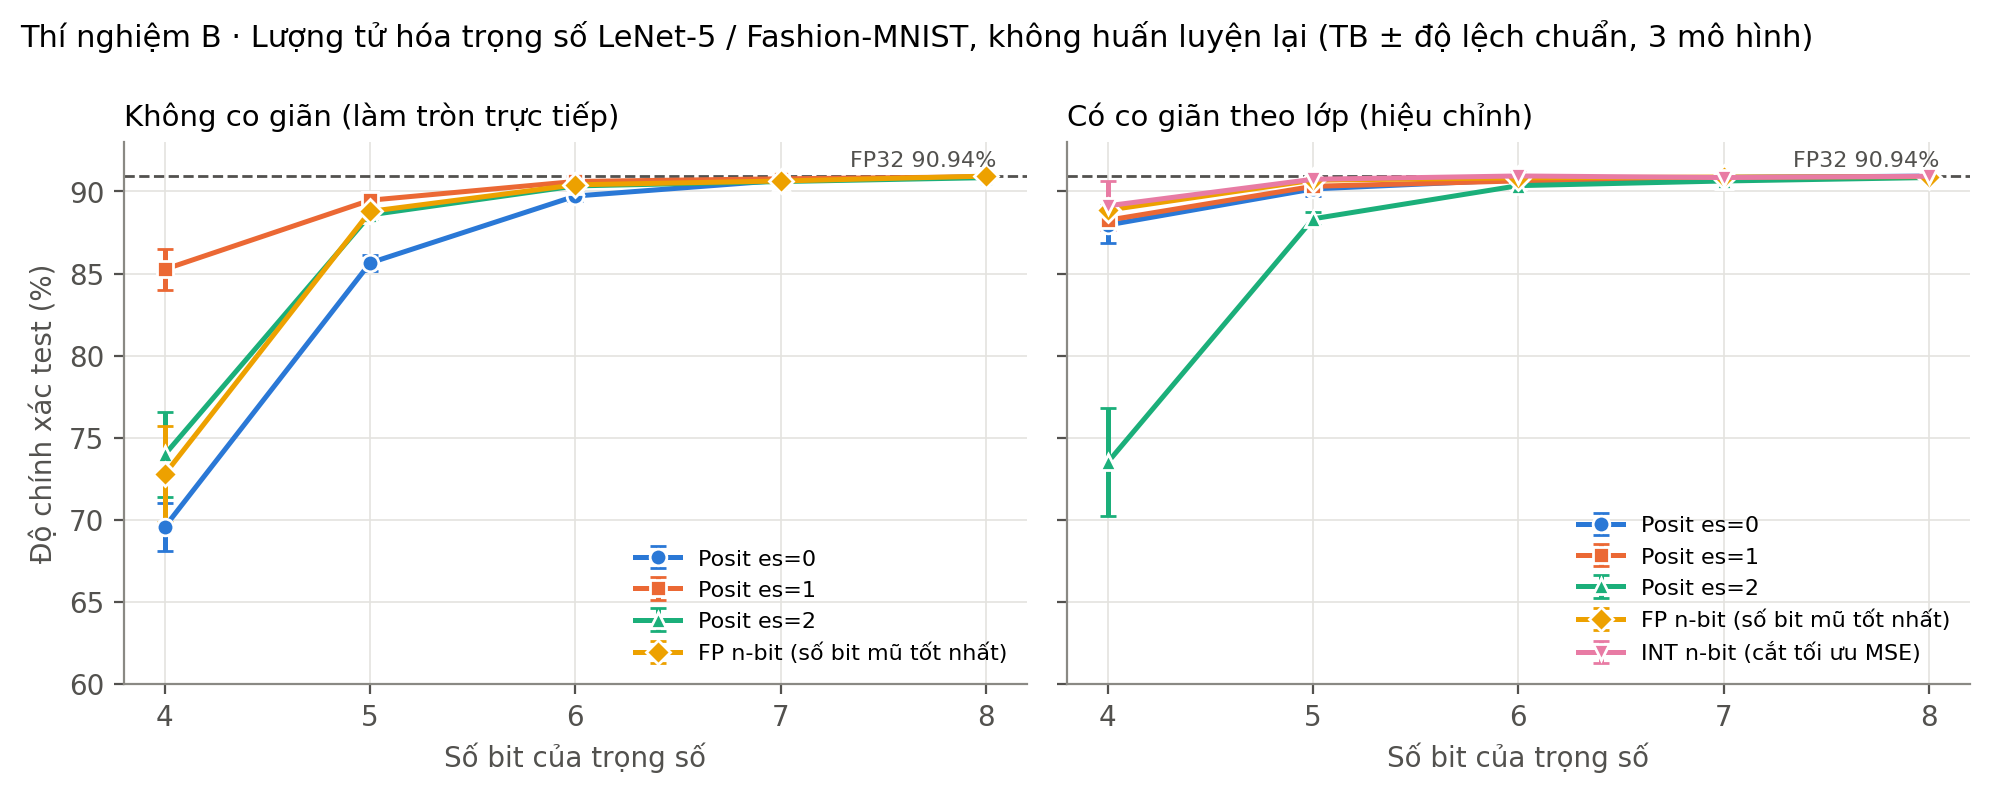
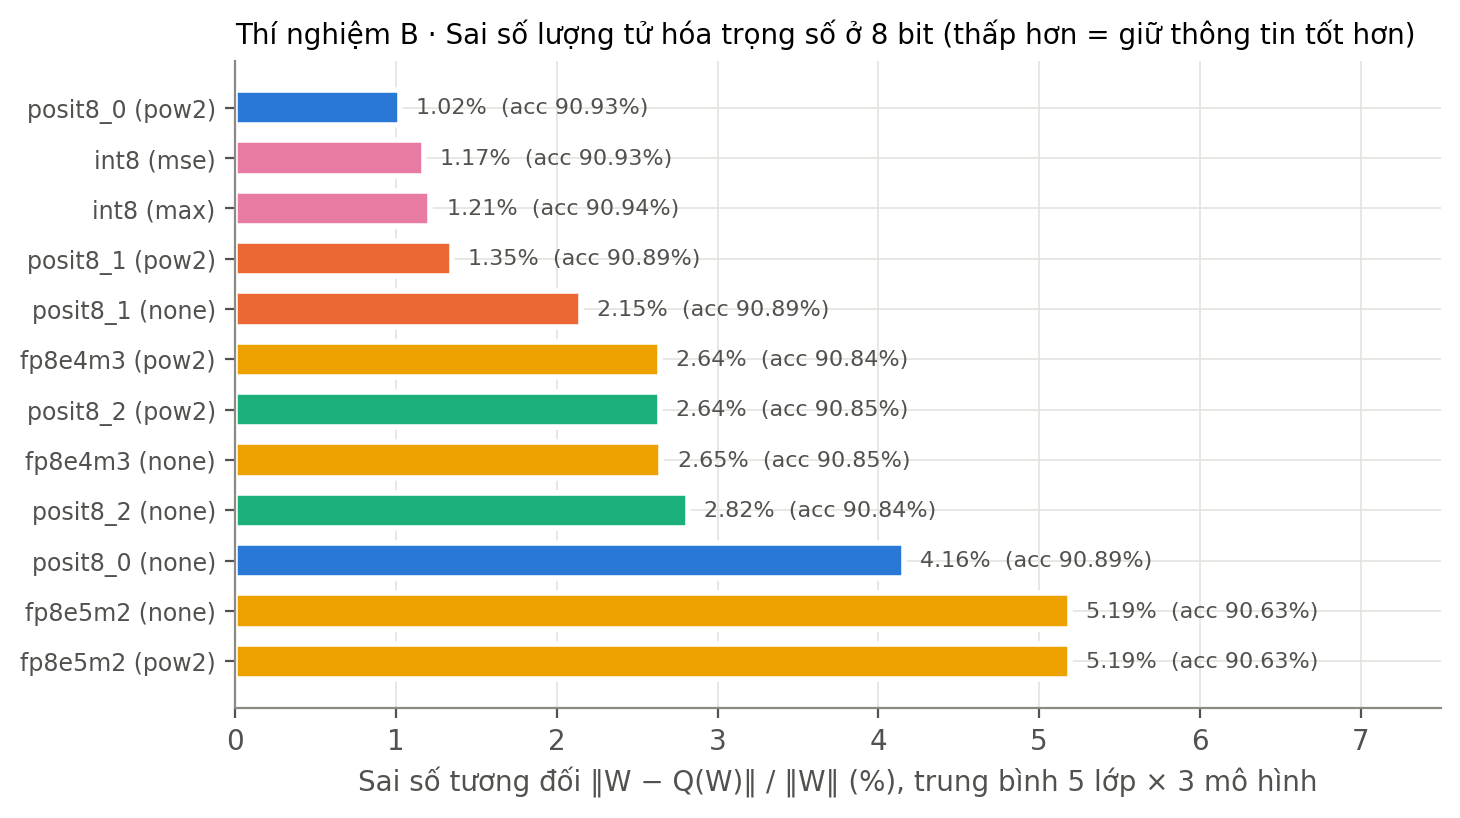
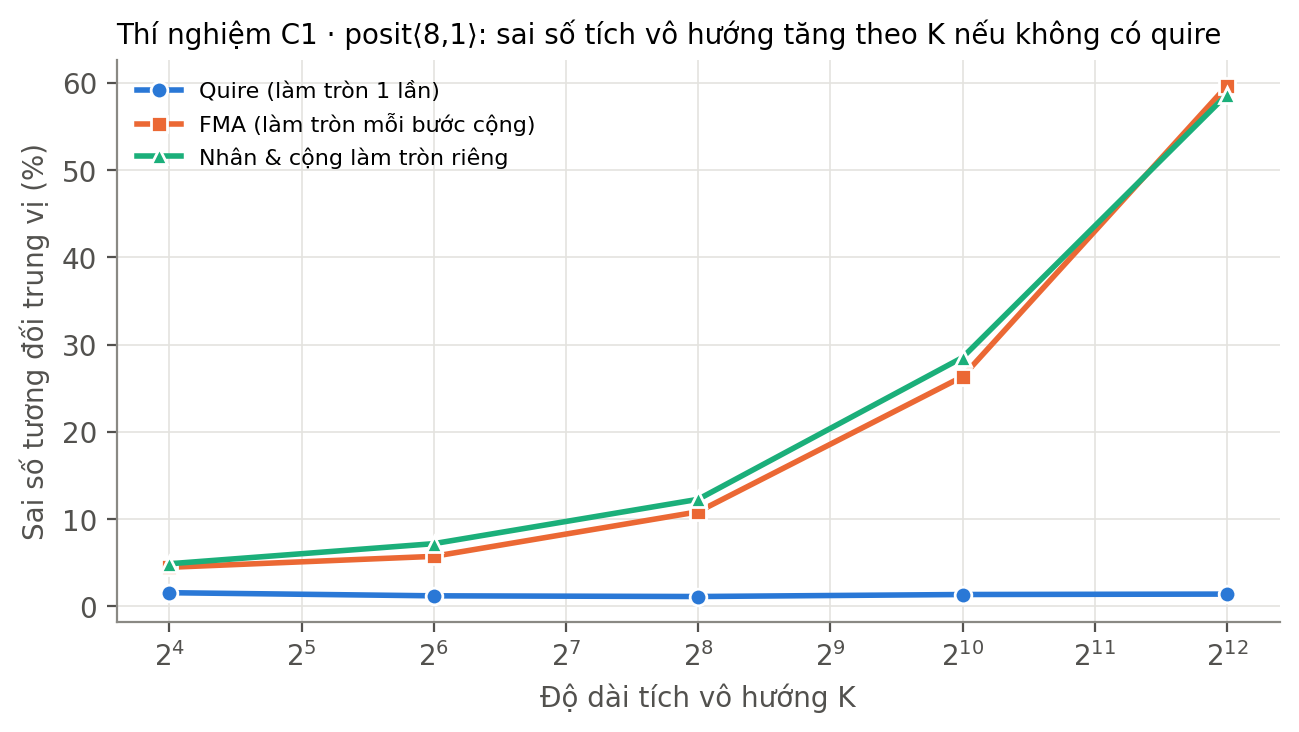
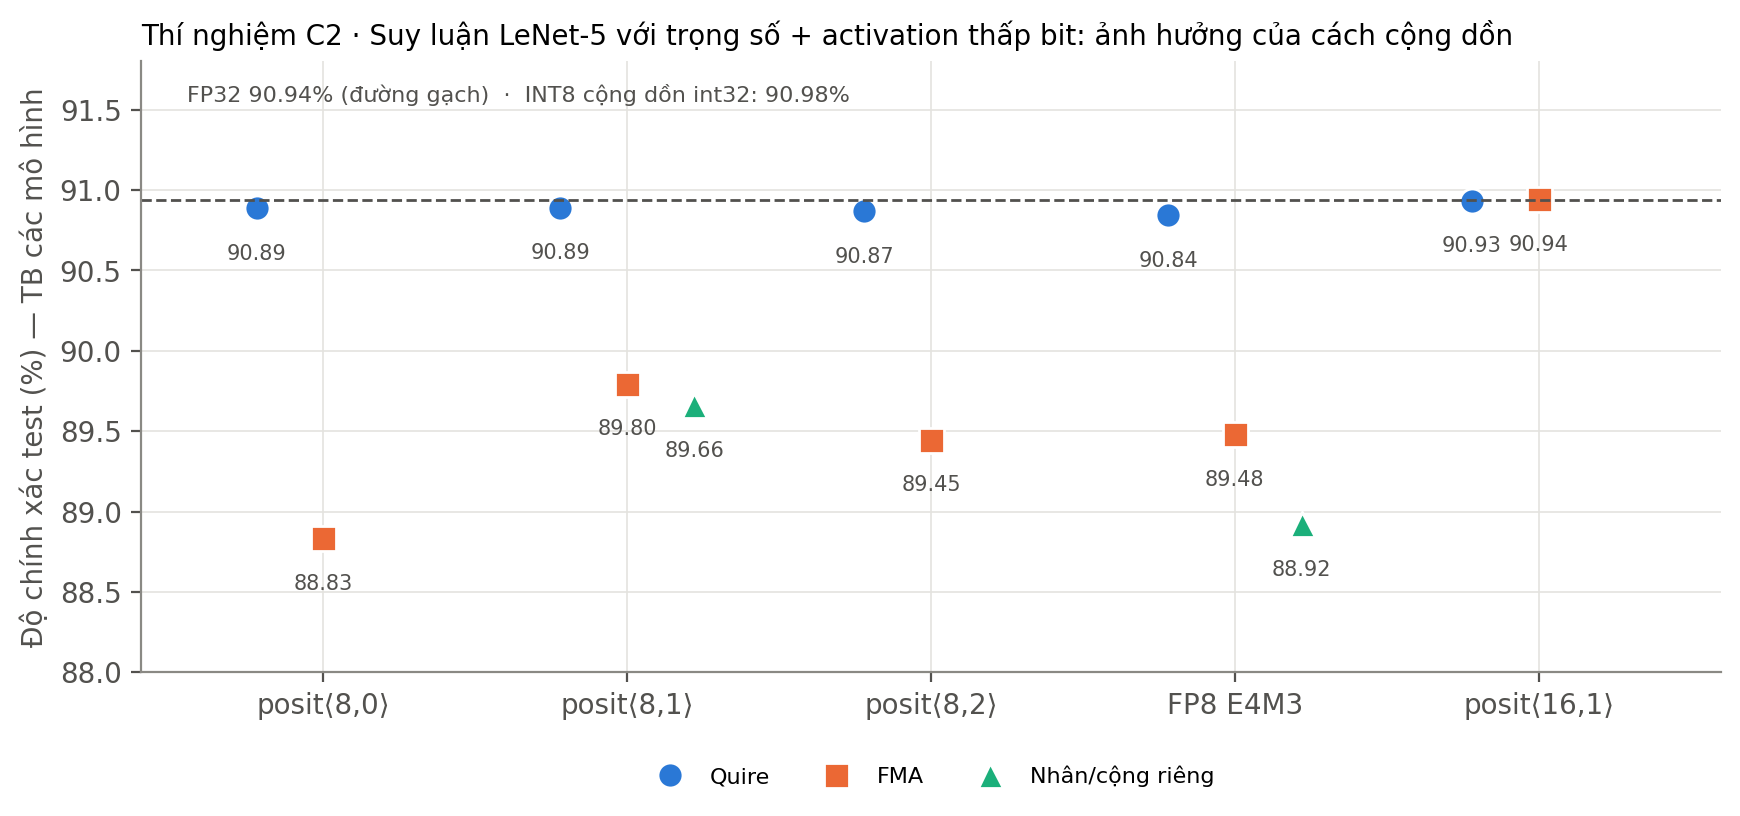
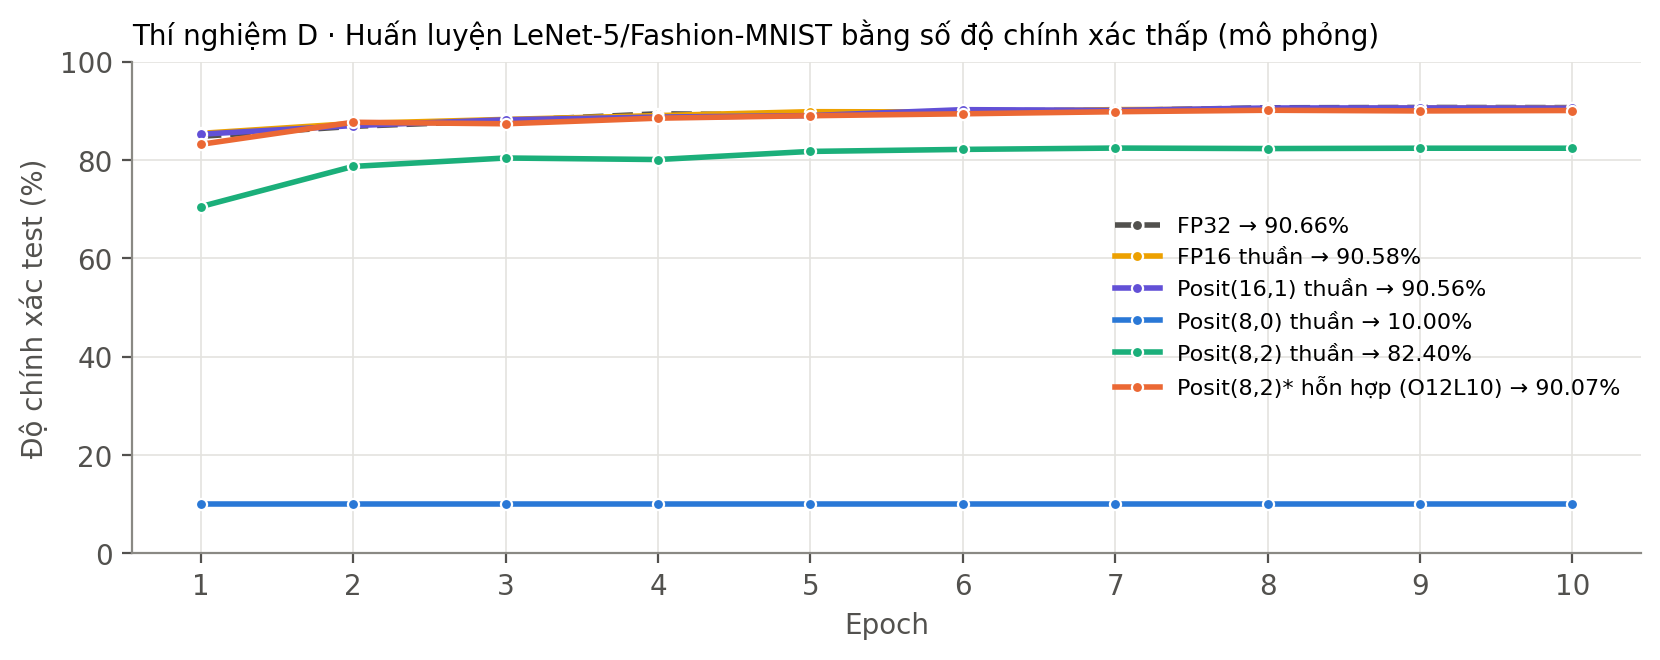

In [ ]:
session.report(['04_expB_weight_ptq.json', '05_expC_quire.json', '06_expD_training.json'], ['B_*.png', 'C*.png', 'D_*.png'])